# **Tarea: CNN compacta con Global Average Pooling**
### Introducción a la Ciencia de Datos
*Alumno: Norman O. Guzmán Chaboya*

En esta tarea se busca una red convolucional con Global Average Pooling (GAP) que supere el 95 % de exactitud de validación en MNIST con menos parámetros entrenables que la CNN base con Flatten. Después se mide qué tan bien reconoce los dígitos cuando cambian de posición. Se usan las mismas particiones, el margen negro de cuatro píxeles, la semilla y la configuración de entrenamiento (20 épocas) de la CNN de referencia

In [1]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow import keras

SEMILLA = 42

## 1. Datos y modelos de referencia

MNIST contiene imágenes de 28×28 en escala de grises de los dígitos 0 a 9. Se toman subconjuntos estratificados de 8,000 imágenes de entrenamiento y 1,500 de validación del conjunto oficial de entrenamiento, y 2,000 de prueba del conjunto oficial de prueba. Cada imagen recibe un margen negro de cuatro píxeles por lado, de modo que la red recibe imágenes de 36×36 y un dígito puede desplazarse hasta cuatro píxeles sin recortarse:

In [2]:
N_ENT, N_VAL, N_PRUEBA = 8000, 1500, 2000
MARGEN = 4

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})


(x_des, y_des), (x_test, y_test) = keras.datasets.mnist.load_data()
i_ent, i_val = train_test_split(
    np.arange(len(y_des)), train_size=N_ENT, test_size=N_VAL,
    stratify=y_des, random_state=SEMILLA,
)
i_prueba, _ = train_test_split(
    np.arange(len(y_test)), train_size=N_PRUEBA, stratify=y_test,
    random_state=SEMILLA,
)

def preparar_imagenes(imagenes):
    imagenes = np.pad(imagenes, ((0, 0), (MARGEN, MARGEN), (MARGEN, MARGEN)))
    return imagenes[..., None].astype(np.float32) / 255.0

X_ent, y_ent = preparar_imagenes(x_des[i_ent]), y_des[i_ent]
X_val, y_val = preparar_imagenes(x_des[i_val]), y_des[i_val]
X_prueba, y_prueba = preparar_imagenes(x_test[i_prueba]), y_test[i_prueba]
FORMA = X_ent.shape[1:]
for nombre, X in [("Entrenamiento", X_ent), ("Validación", X_val), ("Prueba", X_prueba)]:
    print(f"{nombre}: {X.shape}")

Entrenamiento: (8000, 36, 36, 1)
Validación: (1500, 36, 36, 1)
Prueba: (2000, 36, 36, 1)


Los dos modelos de referencia tienen dos convoluciones de 16 filtros de 3×3 con RELU, padding same y un max pooling de 2×2. Difieren solo en cómo llegan los mapas a la capa de diez clases: Flatten aplana los mapas de 18×18×16 en un vector de 5,184 valores, mientras que GAP promedia cada canal y entrega 16. Todos los modelos se entrenan con Adam (tasa 0.001), lotes de 128 y 20 épocas, con la misma semilla:

In [3]:
CAPAS = (16, 16)
LOTE = 128
EPOCAS = 20
TASA = 0.001

def crear_cnn(filtros=CAPAS, padding="same", pooling="max", stride=1, cabeza="flatten"):
    capas = [keras.Input(shape=FORMA)]
    for i, n_filtros in enumerate(filtros):
        capas.append(keras.layers.Conv2D(
            n_filtros, 3, strides=stride if i == 0 else 1,
            padding=padding, activation="relu", name=f"conv_{i + 1}",
        ))
    if pooling == "max":
        capas.append(keras.layers.MaxPooling2D(2, name="pool"))
    elif pooling == "average":
        capas.append(keras.layers.AveragePooling2D(2, name="pool"))
    elif pooling != "sin":
        raise ValueError("pooling debe ser 'max', 'average' o 'sin'")

    if cabeza == "flatten":
        capas.append(keras.layers.Flatten(name="vector"))
    elif cabeza == "gap":
        capas.append(keras.layers.GlobalAveragePooling2D(name="vector"))
    else:
        raise ValueError("cabeza debe ser 'flatten' o 'gap'")

    capas.append(keras.layers.Dense(10, activation="softmax", name="salida"))
    return keras.Sequential(capas, name=f"cnn_{cabeza}")

def lotes(X, y=None, mezclar=False):
    datos = tf.data.Dataset.from_tensor_slices(X if y is None else (X, y))
    if mezclar:
        datos = datos.shuffle(len(X), seed=SEMILLA)
    opciones = tf.data.Options()
    opciones.threading.private_threadpool_size = 2
    return datos.batch(LOTE).with_options(opciones).prefetch(1)

def entrenar(constructor, **configuracion):
    keras.utils.set_random_seed(SEMILLA)
    modelo = constructor(**configuracion)
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=TASA),
        loss="sparse_categorical_crossentropy",
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
    )
    historial = modelo.fit(
        lotes(X_ent, y_ent, mezclar=True),
        validation_data=lotes(X_val, y_val),
        epochs=EPOCAS, verbose=0, shuffle=False,  # lotes() ya mezcla los datos
    ).history
    return modelo, historial

def resumen_cnn(nombre, modelo, historial):
    forma = modelo.get_layer("vector").input.shape[1:]
    return {
        "Modelo": nombre,
        "Parámetros entrenables": sum(int(np.prod(v.shape)) for v in modelo.trainable_weights),
        "Mapas antes del vector": " × ".join(str(d) for d in forma),
        "Exactitud validación (%)": 100 * historial["val_accuracy"][-1],
    }

modelo_flatten, hist_flatten = entrenar(crear_cnn)
modelo_gap, hist_gap = entrenar(crear_cnn, cabeza="gap")
pd.DataFrame([resumen_cnn("CNN + Flatten", modelo_flatten, hist_flatten),
              resumen_cnn("CNN + GAP", modelo_gap, hist_gap)]).round(2)

,Modelo,Parámetros entrenables,Mapas antes del vector,Exactitud validación (%)
0,CNN + Flatten,54330,18 × 18 × 16,96.87
1,CNN + GAP,2650,18 × 18 × 16,43.93


Los dos modelos de referencia reproducen la ejecución guardada: la CNN con Flatten alcanza 96.87 % de exactitud de validación con 54,330 parámetros, y la CNN con GAP, 44.2% con 2,650. GAP reduce los parámetros en 95 % porque la capa densa recibe 16 valores en lugar de 5,184, pero clasifica mal. Antes de promediar hay solo dos convoluciones de 3×3, cuyo campo receptivo es de unos 5×5 píxeles: cada canal detecta trazos cortos, y al promediarlo sobre toda la imagen el vector indica cuánto de cada trazo hay, pero no dónde está, que es justo la información que Flatten conserva.

## 2. Variantes con GAP

Para explorar arquitecturas, la función `crear_gap` recibe la secuencia de capas: un número es una convolución con esa cantidad de filtros y `P` es un max pooling de 2×2, de modo que el pooling puede colocarse entre convoluciones. Todas las convoluciones usan *padding* same, ReLU y el mismo tamaño de kernel, y todas las variantes terminan en GAP y una capa densa de diez clases. Las primeras variantes cambian una sola decisión respecto al GAP base (tamaño del kernel, número de filtros o ubicación del pooling); las siguientes combinan las que funcionaron:

In [4]:
def crear_gap(capas=(16, 16, "P"), kernel=3):
    bloques = [keras.Input(shape=FORMA)]
    n_conv = n_pool = 0
    for capa in capas:
        if capa == "P":
            n_pool += 1
            bloques.append(keras.layers.MaxPooling2D(2, name=f"pool_{n_pool}"))
        else:
            n_conv += 1
            bloques.append(keras.layers.Conv2D(capa, kernel, padding="same", activation="relu", name=f"conv_{n_conv}"))
    bloques += [keras.layers.GlobalAveragePooling2D(name="vector"),
                keras.layers.Dense(10, activation="softmax", name="salida")]
    return keras.Sequential(bloques, name="cnn_gap")

def describir(capas, kernel=3):
    return " → ".join("pool" if c == "P" else f"conv {c}" for c in capas) + f" · kernel {kernel} × {kernel}"

variantes = {
    "GAP base": ("referencia", dict(capas=(16, 16, "P"))),
    "Kernel 5 × 5": ("kernel de 3 a 5 (vs. GAP base)", dict(capas=(16, 16, "P"), kernel=5)),
    "32 filtros": ("de 16 a 32 filtros (vs. GAP base)", dict(capas=(32, 32, "P"))),
    "Pooling intermedio": ("pooling entre las convoluciones (vs. GAP base)", dict(capas=(16, "P", 16))),
    "Dos etapas": ("otro pooling y una convolución de 32", dict(capas=(16, "P", 16, "P", 32))),
    "Dos etapas + pooling": ("pooling antes de GAP (vs. Dos etapas)", dict(capas=(16, "P", 16, "P", 32, "P"))),
    "Tres etapas": ("una convolución más tras el tercer pooling", dict(capas=(16, "P", 16, "P", 16, "P", 32))),
    "Tres etapas, 32 filtros": ("de 16 a 32 filtros en la tercera convolución (vs. Tres etapas)", dict(capas=(16, "P", 16, "P", 32, "P", 32))),
    "Tres etapas, 64 filtros": ("más filtros por etapa", dict(capas=(16, "P", 32, "P", 32, "P", 64))),
    "Dos convoluciones por etapa": ("dos convoluciones por etapa", dict(capas=(16, 16, "P", 32, 32, "P", 64, "P"))),
}

modelos_gap, filas = {}, []
for nombre, (cambio, configuracion) in variantes.items():
    modelo, historial = entrenar(crear_gap, **configuracion)
    modelos_gap[nombre] = modelo
    filas.append({**resumen_cnn(nombre, modelo, historial), "Arquitectura": describir(**configuracion), "Cambio": cambio})

tabla_gap = pd.DataFrame(filas).set_index("Modelo")
tabla_gap.round(2)

,Parámetros entrenables,Mapas antes del vector,Exactitud validación (%),Arquitectura,Cambio
Modelo,,,,,
GAP base,2650,18 × 18 × 16,43.93,conv 16 → conv 16 → pool · kernel 3 × 3,referencia
Kernel 5 × 5,7002,18 × 18 × 16,73.33,conv 16 → conv 16 → pool · kernel 5 × 5,kernel de 3 a 5 (vs. GAP base)
32 filtros,9898,18 × 18 × 32,49.27,conv 32 → conv 32 → pool · kernel 3 × 3,de 16 a 32 filtros (vs. GAP base)
Pooling intermedio,2650,18 × 18 × 16,60.73,conv 16 → pool → conv 16 · kernel 3 × 3,pooling entre las convoluciones (vs. GAP base)
Dos etapas,7450,9 × 9 × 32,90.87,conv 16 → pool → conv 16 → pool → conv 32 · ke...,otro pooling y una convolución de 32
Dos etapas + pooling,7450,4 × 4 × 32,93.20,conv 16 → pool → conv 16 → pool → conv 32 → po...,pooling antes de GAP (vs. Dos etapas)
Tres etapas,9770,4 × 4 × 32,95.00,conv 16 → pool → conv 16 → pool → conv 16 → po...,una convolución más tras el tercer pooling
"Tres etapas, 32 filtros",16698,4 × 4 × 32,95.33,conv 16 → pool → conv 16 → pool → conv 32 → po...,de 16 a 32 filtros en la tercera convolución (...
"Tres etapas, 64 filtros",33194,4 × 4 × 64,96.20,conv 16 → pool → conv 32 → pool → conv 32 → po...,más filtros por etapa


Las tres comparaciones de una sola decisión muestran qué limita al GAP base. Duplicar los filtros casi cuadruplica los parámetros (9,898) y apenas sube la exactitud a 49.33 %: más detectores del mismo tamaño no resuelven el problema. Pasar a kernels de 5 × 5 la sube a 73.20 % con 7,002 parámetros, y mover el pooling entre las dos convoluciones la sube a 60.67 % con exactamente los mismos 2,650. Lo que ayuda es que cada canal vea una región más grande del dígito antes de promediarlo. Siguiendo esa idea, una segunda etapa de pooling y convolución llega a 91.00 %, y añadir un pooling antes de GAP la sube a 93.27 % sin un solo parámetro más. Con una tercera etapa se supera el 95 % (95.20 % con 9,770 parámetros). A partir de ahí, ensanchar la red sube la exactitud poco a cambio de muchos parámetros: 95.53 % con 16,698 y 96.67 % con 35,514, casi el nivel de Flatten con dos tercios de sus parámetros.

Se selecciona, entre las variantes que superan el 95 % de exactitud de validación, la que tiene menos parámetros entrenables:

Variantes sobre 95 %: 3 de 10
Seleccionada: Tres etapas, 32 filtros (conv 16 → pool → conv 16 → pool → conv 32 → pool → conv 32 · kernel 3 × 3)
Parámetros: 16,698 contra 54,330 de Flatten, una reducción de 37,632 (69.3%)


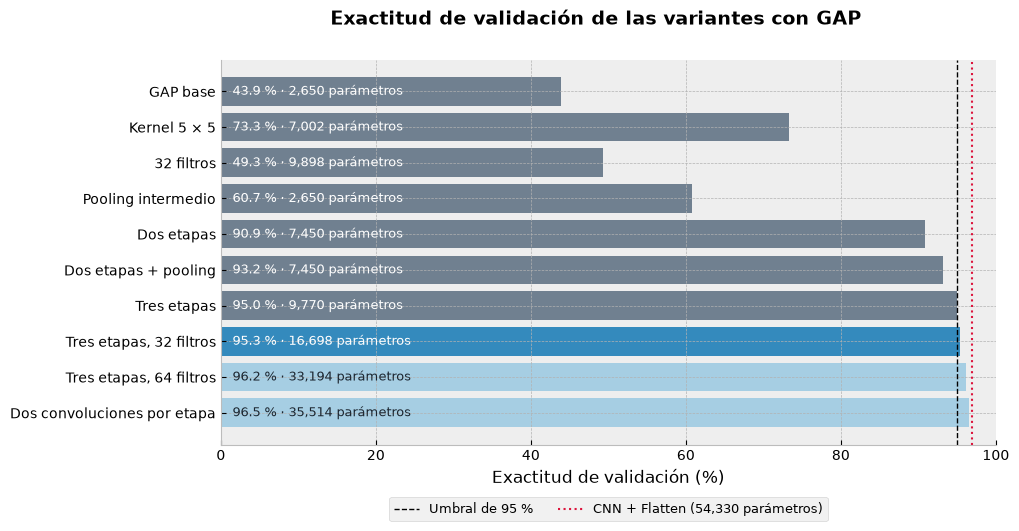

In [5]:
UMBRAL = 95
aprobadas = tabla_gap[tabla_gap["Exactitud validación (%)"] > UMBRAL]
seleccion = aprobadas["Parámetros entrenables"].idxmin()
modelo_sel = modelos_gap[seleccion]
p_flatten = sum(int(np.prod(v.shape)) for v in modelo_flatten.trainable_weights)
p_sel = tabla_gap.loc[seleccion, "Parámetros entrenables"]
print(f"Variantes sobre {UMBRAL} %: {len(aprobadas)} de {len(tabla_gap)}")
print(f"Seleccionada: {seleccion} ({tabla_gap.loc[seleccion, 'Arquitectura']})")
print(f"Parámetros: {p_sel:,} contra {p_flatten:,} de Flatten, una reducción de {p_flatten - p_sel:,} ({1 - p_sel / p_flatten:.1%})")

with plt.style.context("bmh"):
    fig, ax = plt.subplots(figsize=(10, 5))
    acc = tabla_gap["Exactitud validación (%)"]
    colores = np.where(tabla_gap.index == seleccion, "#348ABD", np.where(acc > UMBRAL, "#A6CEE3", "slategrey"))
    ax.barh(tabla_gap.index, acc, color=colores)
    for i, (a, p, c) in enumerate(zip(acc, tabla_gap["Parámetros entrenables"], colores)):
        ax.text(1.5, i, f"{a:.1f} % · {p:,} parámetros", va="center", fontsize=9,
                color="#1C2630" if c == "#A6CEE3" else "white")
    ax.axvline(UMBRAL, color="black", linestyle="--", linewidth=1, label=f"Umbral de {UMBRAL} %")
    ax.axvline(100 * hist_flatten["val_accuracy"][-1], color="crimson", linestyle=":", linewidth=1.5,
               label=f"CNN + Flatten ({p_flatten:,} parámetros)")
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel("Exactitud de validación (%)")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=9)
    fig.suptitle("Exactitud de validación de las variantes con GAP", fontweight="bold", fontsize=14)
    plt.show()

Cuatro de las diez variantes superan el 95% de exactitud de validación, y la de menos parámetros es la de tres etapas: 9,770 parámetros y 95.2%, contra 54,330 de Flatten, es decir, 44,560 parámetros menos (82%). Respecto al GAP base cambian tres cosas: el pooling se reparte entre las convoluciones, en tres etapas, de modo que la última convolución tiene un campo receptivo de unos 38 píxeles y cubre el dígito completo; la última capa tiene 32 canales en lugar de 16, lo que da un vector más largo a la capa densa, y un pooling antes de GAP conserva las respuestas más fuertes antes de promediar. Su margen sobre el umbral es pequeño, por lo que otra semilla podría dejarla justo por debajo. La siguiente variante, con 32 filtros en la tercera convolución, ofrece un margen algo mayor.

## 3. Efecto del desplazamiento

Se evalúan la CNN con Flatten, el GAP base y el GAP seleccionado sobre las mismas imágenes de prueba, con los pesos ya entrenados. Primero en su posición original y después desplazadas 2 y 4 píxeles hacia arriba, abajo, izquierda y derecha; los píxeles que quedan vacíos son negros. A 2 y 4 píxeles se promedia la exactitud de las cuatro direcciones:

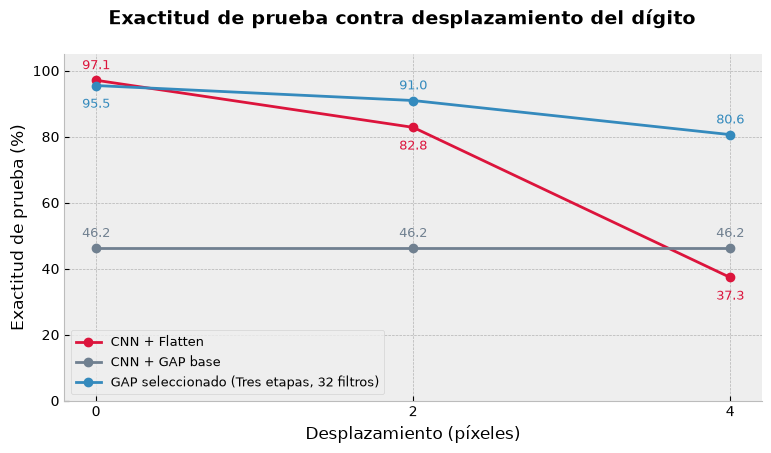

,0 px (%),2 px (%),4 px (%),Caída a 4 px (pp)
Modelo,,,,
CNN + Flatten,97.10,82.82,37.34,59.76
CNN + GAP base,46.25,46.25,46.25,0.00
"GAP seleccionado (Tres etapas, 32 filtros)",95.50,90.96,80.62,14.88


In [6]:
def desplazar(imagenes, dy, dx):
    if max(abs(dy), abs(dx)) > MARGEN:
        raise ValueError("Usa un desplazamiento dentro del margen de la imagen.")
    alto, ancho = imagenes.shape[1:3]
    resultado = np.zeros_like(imagenes)
    origen_y = slice(max(-dy, 0), alto - max(dy, 0))
    origen_x = slice(max(-dx, 0), ancho - max(dx, 0))
    destino_y = slice(max(dy, 0), alto - max(-dy, 0))
    destino_x = slice(max(dx, 0), ancho - max(-dx, 0))
    resultado[:, destino_y, destino_x, :] = imagenes[:, origen_y, origen_x, :]
    return resultado

def predecir(modelo, imagenes):
    return modelo.predict(lotes(imagenes), verbose=0).argmax(axis=1)

modelos = {"CNN + Flatten": modelo_flatten, "CNN + GAP base": modelo_gap, f"GAP seleccionado ({seleccion})": modelo_sel}
distancias = (0, 2, 4)
exactitudes = {nombre: [100 * np.mean(predecir(modelo, X_prueba) == y_prueba)] for nombre, modelo in modelos.items()}
for distancia in distancias[1:]:
    direcciones = ((0, distancia), (0, -distancia), (distancia, 0), (-distancia, 0))
    imagenes = [desplazar(X_prueba, dy, dx) for dy, dx in direcciones]
    for nombre, modelo in modelos.items():
        exactitudes[nombre].append(float(np.mean([100 * np.mean(predecir(modelo, X) == y_prueba) for X in imagenes])))

tabla = pd.DataFrame.from_dict(exactitudes, orient="index", columns=[f"{d} px (%)" for d in distancias])
tabla["Caída a 4 px (pp)"] = tabla["0 px (%)"] - tabla["4 px (%)"]
tabla.index.name = "Modelo"

with plt.style.context("bmh"):
    fig, ax = plt.subplots(figsize=(9, 4.5))
    desfases = ((8, -16, -16), (8, 8, 8), (-16, 8, 8))   # posición de cada etiqueta para que no se encimen
    for (nombre, valores), color, dys in zip(exactitudes.items(), ("crimson", "slategrey", "#348ABD"), desfases):
        ax.plot(distancias, valores, marker="o", linewidth=2, label=nombre, color=color)
        for d, v, dy in zip(distancias, valores, dys):
            ax.annotate(f"{v:.1f}", (d, v), textcoords="offset points", xytext=(0, dy), ha="center", fontsize=9, color=color)
    ax.set(xlabel="Desplazamiento (píxeles)", ylabel="Exactitud de prueba (%)", xticks=distancias, ylim=(0, 105))
    ax.legend(loc="lower left", fontsize=9)
    fig.suptitle("Exactitud de prueba contra desplazamiento del dígito", fontweight="bold", fontsize=14)
    plt.show()

tabla.round(2)

Sin desplazamiento, Flatten es el más exacto en prueba, seguido del GAP seleccionado (94.90 %, ligeramente bajo el 95% que obtuvo en validación), mientras que el GAP base se queda en 46.25%. Al mover los dígitos, Flatten cae a 82.78 % a 2 píxeles y a ~37% a 4, una caída de 59.82 puntos: sus pesos densos están atados a posiciones concretas de los mapas. El GAP base prácticamente no cambia, pero conserva una exactitud baja en todas las posiciones. El GAP seleccionado combina ambas cosas: cae 17.52 puntos, y a 4 píxeles conserva aprox. 77%, 40 puntos más que flatten. No es invariante del todo, porque los poolings intermedios y los bordes de la imagen todavía dependen de la posición, pero el promedio final hace que importe mucho menos dónde está el trazo.

## 4. Conclusiones

El cambio más importante para que GAP superara el 95% fue repartir el pooling entre las convoluciones, en tres etapas, para que los canales que llegan al promedio representen partes grandes del dígito y no trazos sueltos. Con los mismos 2,650 parámetros, solo mover el pooling subió la exactitud de ~44% a 60.67%, mientras que duplicar los filtros sin cambiar su campo receptivo apenas la subió a 49.33%. El GAP seleccionado tiene 9,770 parámetros entrenables, 44,560 menos que la CNN con Flatten con ~95% de exactitud de validación.

El GAP seleccionado reconoce mejor los dígitos desplazados que Flatten. Sin desplazamiento, Flatten es algo más exacto , pero desde 2 píxeles la relación se invierte (88.76  contra 82.78%), y a 4 píxeles la diferencia es de 40 puntos (77.38% contra 37.28%). El GAP base, aunque casi no cambia con el desplazamiento, no es una alternativa, porque su estabilidad se da sobre una exactitud de 46%. Estas cifras provienen de una sola semilla y de la exactitud al final de las 20 épocas, así que diferencias de pocas décimas entre variantes no deben tomarse como definitivas.

### Declaración de uso de Inteligencia Artificial Generativa

Para esta tarea se utilizó Claude para diseñar y entrenar las variantes de la red convolucional con Global Average Pooling, en particular la función que construye arquitecturas con el pooling entre convoluciones, y para generar las gráficas de exactitud de las variantes y de desplazamiento

In [7]:
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("matplotlib  ", matplotlib.__version__)
print("scikit-learn", sklearn.__version__)
print("tensorflow  ", tf.__version__)
print("keras       ", keras.__version__)

numpy        2.5.2
pandas       3.0.5
matplotlib   3.11.0
scikit-learn 1.9.0
tensorflow   2.20.0
keras        3.15.1
